# Notebook 1: Static Spiral Drawing Data Preparation and Feature Extraction

### 1: Downloading dataset from the web
### 2: Extract HW static spirals
### 3: Calculate absolute acceleration, speed variability, and pressure variability
### 4: Create results table
### 5: Visualize
### 6: Save results



In [ ]:
# Importing libraries
import requests
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle
import shutil
from google.colab import files

#### 1: Downloading dataset from the web

In [ ]:
# Download the dataset from UCI
url = "https://archive.ics.uci.edu/static/public/395/parkinson+disease+spiral+drawings+using+digitized+graphics+tablet.zip"
response = requests.get(url)
response.raise_for_status()

# Extract the dataset
with open("dataset.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("dataset.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

# Find participant recording files (excluding README and MATLAB files)
txt_files = [
    file for file in Path("dataset").rglob("*.txt")
    if file.name.lower() != "readme.txt"
]

print(f"Found {len(txt_files)} recording files!")

Found 77 recording files!


#### 2: Extract HW Static Spiral Recordings

This dataset actual contains 2 seperate datasets. HW includes control healthy patients and patients with Parkinson's disease, while New contains only patients with Parkinson's disease.



In [ ]:
# Define the measurement columns
column_names = ["X", "Y", "Z", "Pressure", "GripAngle", "Timestamp", "TestID"]

# Select only HW recording files
hw_files = [file for file in txt_files if "hw_dataset" in file.parts]

# Keep the static spiral portion of each HW recording
static_spirals = {}
for file in hw_files:
    df = pd.read_csv(file, sep=";", names=column_names)
    static_spiral = df[df["TestID"] == 0].copy()
    if not static_spiral.empty:
        static_spirals[str(file)] = static_spiral

print(f"HW recording files: {len(hw_files)}")
print(f"HW static spiral recordings: {len(static_spirals)}")

# Preview one static spiral
first_file = next(iter(static_spirals))
display(static_spirals[first_file].head())

HW recording files: 40
HW static spiral recordings: 40


,X,Y,Z,Pressure,GripAngle,Timestamp,TestID
0,281,201,0,4,900,6945632,0
1,281,201,0,9,900,6945641,0
2,280,201,0,9,900,6945650,0
3,280,201,0,9,890,6945659,0
4,281,201,12,16,900,6945992,0


#### 3: Calculate the Three Features

3.1: Mean absolute acceleration. This measures the average magnitude of chnage in speed per timestamp interval as a simpler way to calculate smoothness.

3.2: Speed variability. This is the standard deviation of speed within the recording.

3.3: Pressure variability. This is the standard deviation of pen pressure within the recording.

3.4: Combine these three features for each recording

Please note that intervals with nonpositive time differences are excluded from speed and acceleration calculations. Valid zero speeds are retained. The raw coordinate and timestamp units are used.

In [ ]:
# 3.1 Mean absolute acceleration

# Calculate mean absolute acceleration for each HW static spiral
acceleration_results = {}

for file, df in static_spirals.items():
    df["Distance"] = np.sqrt(df["X"].diff()**2 + df["Y"].diff()**2)
    df["TimeDifference"] = df["Timestamp"].diff()
    df["Speed"] = df["Distance"] / df["TimeDifference"].where(df["TimeDifference"] > 0)
    df["Acceleration"] = df["Speed"].diff() / df["TimeDifference"].where(df["TimeDifference"] > 0)
    df["AbsoluteAcceleration"] = df["Acceleration"].abs()
    acceleration_results[file] = df["AbsoluteAcceleration"].mean()

print(f"Calculated mean absolute acceleration for {len(acceleration_results)} recordings.")
display(static_spirals[first_file][["Distance", "TimeDifference", "Speed", "Acceleration", "AbsoluteAcceleration"]].head())

Calculated mean absolute acceleration for 40 recordings.


,Distance,TimeDifference,Speed,Acceleration,AbsoluteAcceleration
0,NaN,NaN,NaN,NaN,NaN
1,0.0,9.0,0.000000,NaN,NaN
2,1.0,9.0,0.111111,0.012346,0.012346
3,0.0,9.0,0.000000,-0.012346,0.012346
4,1.0,333.0,0.003003,0.000009,0.000009


In [ ]:
# 3.2 Speed variability

# Calculate speed variability for each HW static spiral
speed_variability_results = {}

for file, df in static_spirals.items():
    speed_variability_results[file] = df["Speed"].std()

print(f"Calculated speed variability for {len(speed_variability_results)} recordings.")
print("Example speed variability:", speed_variability_results[first_file])

Calculated speed variability for 40 recordings.
Example speed variability: 0.06349782586347037


In [ ]:
# 3.3 Pressure variability

# Calculate pressure variability for each HW static spiral
pressure_variability_results = {}

for file, df in static_spirals.items():
    pressure_variability_results[file] = df["Pressure"].std()

print(f"Calculated pressure variability for {len(pressure_variability_results)} recordings.")
print("Example pressure variability:", pressure_variability_results[first_file])

Calculated pressure variability for 40 recordings.
Example pressure variability: 118.1300707483385


In [ ]:
# 3.4 Combine the three features for each recording

feature_results = []

for file in static_spirals:
    path = Path(file)
    feature_results.append({
        "ParticipantID": path.stem,
        "Diagnosis": "Control" if "control" in path.parts else "Parkinson",
        "Dataset": "HW",
        "MeanAbsoluteAcceleration": acceleration_results[file],
        "SpeedVariability": speed_variability_results[file],
        "PressureVariability": pressure_variability_results[file]
    })

print(f"Combined features for {len(feature_results)} recordings.")

Combined features for 40 recordings.


#### 4: Create a results table

In [ ]:
# Organize the extracted features into one results table
features_df = pd.DataFrame(feature_results)
features_df = features_df.sort_values(["Diagnosis", "ParticipantID"]).reset_index(drop=True)

display(features_df)
print(f"Total HW static spiral recordings: {len(features_df)}")
print("\nRecordings per diagnosis:")
print(features_df["Diagnosis"].value_counts())
print("\nMissing feature values:")
print(features_df[["MeanAbsoluteAcceleration", "SpeedVariability", "PressureVariability"]].isna().sum())


,ParticipantID,Diagnosis,Dataset,MeanAbsoluteAcceleration,SpeedVariability,PressureVariability
0,C_0001,Control,HW,0.012615,0.083299,74.242886
1,C_0002,Control,HW,0.014480,0.078750,42.284534
2,C_0003,Control,HW,0.008413,0.060583,58.967757
3,C_0004,Control,HW,0.012958,0.077356,56.782572
4,C_0005,Control,HW,0.011480,0.087282,84.222319
5,C_0006,Control,HW,0.012447,0.081133,54.231898
6,C_0007,Control,HW,0.012097,0.081157,61.416454
7,C_0008,Control,HW,0.012698,0.074207,63.778336
8,C_0009,Control,HW,0.011551,0.069863,57.629182
9,C_0010,Control,HW,0.012546,0.075371,100.919311


Total HW static spiral recordings: 40

Recordings per diagnosis:
Diagnosis
Parkinson    25
Control      15
Name: count, dtype: int64

Missing feature values:
MeanAbsoluteAcceleration    0
SpeedVariability            0
PressureVariability         0
dtype: int64


#### 5: Visualize

5.1: Mean absolute acceleration

5.2: Speed Variability

5.3: Pressure Variability

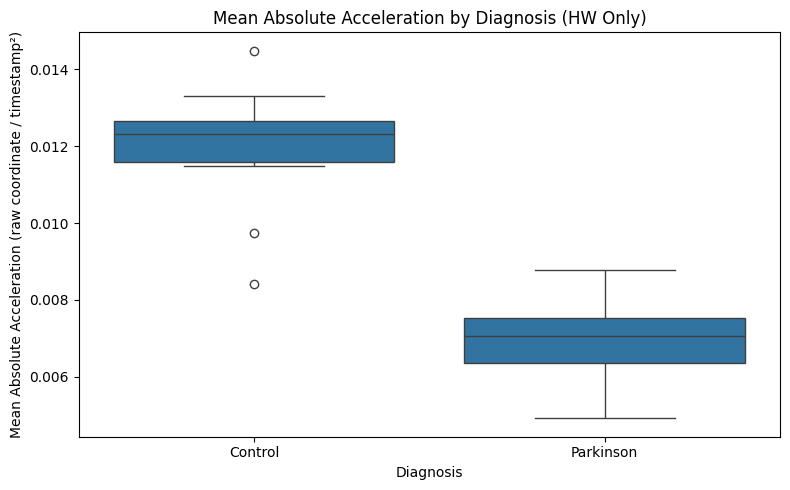

In [ ]:
# 5.1 Mean absolute acceleration

plt.figure(figsize=(8, 5))
sns.boxplot(data=features_df, x="Diagnosis", y="MeanAbsoluteAcceleration", order=["Control", "Parkinson"])
plt.title("Mean Absolute Acceleration by Diagnosis (HW Only)")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Absolute Acceleration (raw coordinate / timestamp²)")
plt.tight_layout()
plt.show()

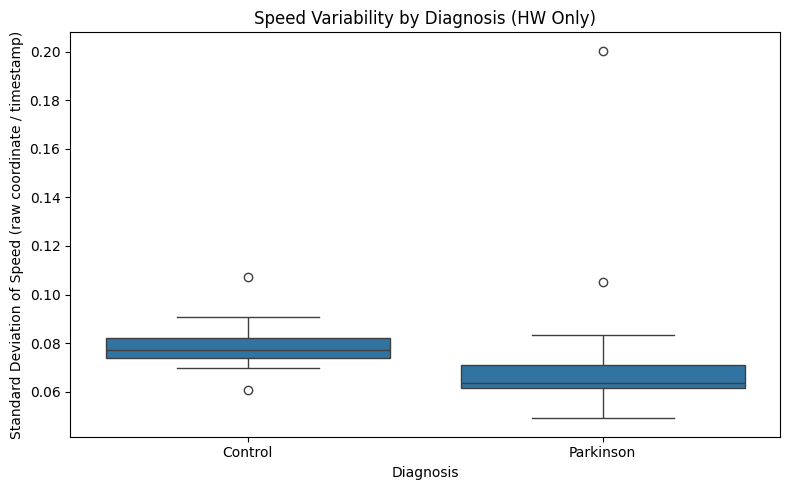

In [ ]:
# 5.2 Speed Variability

plt.figure(figsize=(8, 5))
sns.boxplot(data=features_df, x="Diagnosis", y="SpeedVariability", order=["Control", "Parkinson"])
plt.title("Speed Variability by Diagnosis (HW Only)")
plt.xlabel("Diagnosis")
plt.ylabel("Standard Deviation of Speed (raw coordinate / timestamp)")
plt.tight_layout()
plt.show()

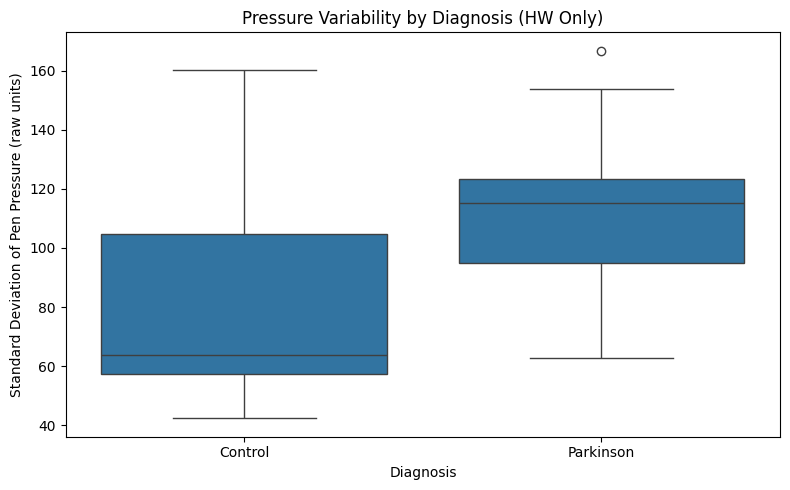

In [ ]:
# 5.3 Pressure Variability
plt.figure(figsize=(8, 5))
sns.boxplot(data=features_df, x="Diagnosis", y="PressureVariability", order=["Control", "Parkinson"])
plt.title("Pressure Variability by Diagnosis (HW Only)")
plt.xlabel("Diagnosis")
plt.ylabel("Standard Deviation of Pen Pressure (raw units)")
plt.tight_layout()
plt.show()

#### 6: Save results

In [ ]:
# Create folders
output_folder = "Notebook1_Results"
os.makedirs(f"{output_folder}/Static_Spirals", exist_ok=True)

# 1. Save results table with all three extracted features
features_df.to_csv(
    f"{output_folder}/Feature_Results.csv",
    index=False
)

# 2. Save filtered HW static spiral recordings
for path, df in static_spirals.items():

    # Extract participant filename from full path
    filename = Path(path).stem

    # Save each recording as a CSV file
    df.to_csv(
        f"{output_folder}/Static_Spirals/{filename}.csv",
        index=False
    )

# 3. Create ZIP file
shutil.make_archive(
    "Notebook1_Results",
    "zip",
    output_folder
)

# 4. Download ZIP directly to your computer
files.download("Notebook1_Results.zip")

print("Notebook 1 results saved successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Notebook 1 results saved successfully!
